# Aula 03 - Hiperparâmetros - Parte I (19.08.2026)

# Setup

In [3]:
# Importar bibliotecas utilizadas no notebook

import numpy as np                              # Computação numérica
import matplotlib.pyplot as plt                 # Geração de gráficos
import time                                     # Medição do tempo de treinamento

from sklearn.model_selection import train_test_split  # Separação entre treino e teste

import tensorflow as tf                         # Construção e treinamento de redes neurais
from tensorflow import keras                    # API de alto nível do TensorFlow
from tensorflow.keras import layers             # Construção das camadas da rede

# Definir semente para tornar os experimentos reproduzíveis

np.random.seed(42)
tf.random.set_seed(42)

# Exibir gráficos no notebook

%matplotlib inline

In [4]:
# Carregar conjunto de dados utilizado nos experimentos

dados = np.load("fashion_mnist.npz")

# Exibir informações básicas sobre o conjunto de dados

print(f"Quantidade de instâncias: {dados['X_train'].shape[0] + dados['X_test'].shape[0]}")
print(f"Dimensão das imagens: {dados['X_train'].shape[1]} x {dados['X_train'].shape[2]} pixels")
print(f"Quantidade de pixels por imagem: {dados['X_train'].shape[1] * dados['X_train'].shape[2]}")
print(f"Quantidade de classes: {len(np.unique(dados['y_train']))}")

Quantidade de instâncias: 70000
Dimensão das imagens: 28 x 28 pixels
Quantidade de pixels por imagem: 784
Quantidade de classes: 10


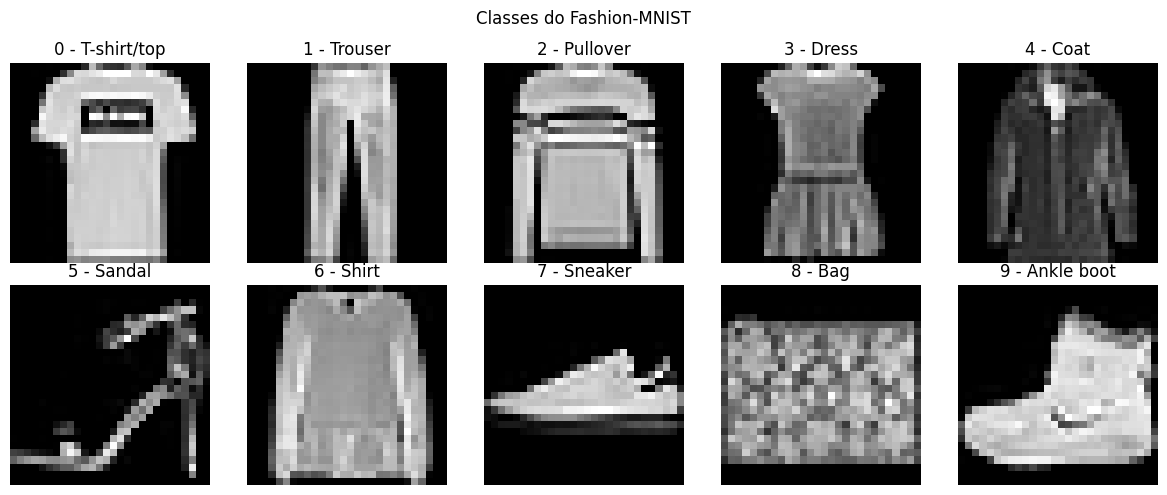

In [5]:
# Definir nomes das classes do Fashion-MNIST

nomes_classes = ["T-shirt/top",    "Trouser",    "Pullover",    "Dress",    "Coat",    "Sandal",    "Shirt",    "Sneaker",    "Bag",    "Ankle boot"]

# Visualizar uma imagem de cada classe do conjunto de dados

plt.figure(figsize=(12, 5))

for classe in range(10):

    # Localizar a primeira imagem pertencente à classe
    indice = np.where(dados["y_train"] == classe)[0][0]

    plt.subplot(2, 5, classe + 1)
    plt.imshow(dados["X_train"][indice], cmap="gray")
    plt.title(f"{classe} - {nomes_classes[classe]}")
    plt.axis("off")

# Configurar o gráfico

plt.suptitle("Classes do Fashion-MNIST")
plt.tight_layout()

plt.show()

## Perguntas

1. Quantas variáveis de entrada e quantas classes existem?
    
    R: 784 variáveis de entrada e são 10 classes


2. O que representa cada variável de entrada neste conjunto de dados?

    R: representa a intensidade da escala de cinza de cada pixel

3. Por que um problema com essa quantidade de variáveis e classes pode ser interessante para avaliar diferentes arquiteturas e hiperparâmetros de uma RN?

    R: O problema de análise de imagem mais "simples", 28x28 e apenas 10 classes definidas permitem uma melhor análise do trabalho de observar os testes dos hiperparametros.

# Split dos Dados

In [6]:
# Preparar os dados para treinamento dos modelos

# Recuperar variáveis de entrada e variável alvo
X_train = dados["X_train"]
y_train = dados["y_train"]

X_test = dados["X_test"]
y_test = dados["y_test"]

# Transformar cada imagem 28x28 em um vetor com 784 variáveis de entrada
X_train = X_train.reshape(X_train.shape[0], 28 * 28)
X_test = X_test.reshape(X_test.shape[0], 28 * 28)

# Normalizar os valores dos pixels para o intervalo entre 0 e 1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Exibir quantidade de instâncias e variáveis de entrada
print(f"Treinamento: {len(X_train)} instâncias")
print(f"Teste: {len(X_test)} instâncias")
print(f"Variáveis de entrada: {X_train.shape[1]}")

Treinamento: 60000 instâncias
Teste: 10000 instâncias
Variáveis de entrada: 784


# Construção e Treinamento da RN

In [7]:
# Construir modelo de referência

model = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: ReLU
    layers.Dense(10, activation="softmax")      # Saída: Softmax
])

# Configurar processo de treinamento

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),   # Otimizador Adam e taxa de aprendizado
    loss="sparse_categorical_crossentropy",                 # Função de perda
    metrics=["accuracy"]                                    # Métrica de avaliação
)

# Exibir arquitetura do modelo

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

## Perguntas

4. Quantas camadas ocultas possui a rede e quantos neurônios existem nessa camada?

    R: 1 camada oculta com 128 neuronios

5. Qual função de ativação foi utilizada na camada oculta? Qual é seu papel?

    R: foi utilizada a ReLU que possui e traz uma função de ativação não linear para saída dde cada neurônio

6. Por que a camada de saída possui 10 neurônios e utiliza a função Softmax?

    R: Por se tratar de um rpoblema de classificação entre 10 classes ele possuii 10 saídas distintas e a função softmax trará a probabilidade daquele conjunto de pixel classicar a figura a uma determinada classe

7. Qual função de perda foi escolhida e por que ela é adequada para este problema?

    R: Classificação Binária (Cross-Entropy) e ela é adequada pois penaliza o modelo de acordo com a probabilidade atribuída a classe correta, penalizando as previsões confiente e as incorretas.

8. Qual otimizador e qual taxa de aprendizado foram definidos?

    R: o Otimizador utilizado foi o Adam com a taxa de 0.001

9. O que acontece se alterarmos `shape=(784,)` para outro valor? Por quê?

    R: ocorre o erro de Shape Mismatch pois a entrada não bate com a quantidade de atributos, impedindo o início do treinamento.

10. Quantos parâmetros treináveis possui a rede? Como esse valor é calculado a partir da quantidade de entradas, neurônios, pesos e biases?

    R: 100.480 parametros. Esse valor é calculado pela multiplicação das entradas pelo neurinios com a soma dos parametros do proprio neuronio.

In [8]:
# Treinar modelo de referência

inicio = time.time()

historico = model.fit(
    X_train,
    y_train,
    epochs=20,             # Número de épocas
    batch_size=128,        # Tamanho do lote
    validation_split=0.20, # Utilizar 20% do treinamento para validação
    verbose=1
)

fim = time.time()

# Exibir tempo total de treinamento

print(f"\nTempo de treinamento: {fim - inicio:.2f} segundos")

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8014 - loss: 0.5809 - val_accuracy: 0.8440 - val_loss: 0.4487
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8541 - loss: 0.4149 - val_accuracy: 0.8593 - val_loss: 0.4055
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8671 - loss: 0.3756 - val_accuracy: 0.8681 - val_loss: 0.3764
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 9ms/step - accuracy: 0.8744 - loss: 0.3496 - val_accuracy: 0.8723 - val_loss: 0.3627
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8816 - loss: 0.3295 - val_accuracy: 0.8743 - val_loss: 0.3525
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 7ms/step - accuracy: 0.8872 - loss: 0.3127 - val_accuracy: 0.8762 - val_loss: 0.3459
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8925 - loss: 0.2974 - val_accuracy: 0.8772 - val_loss: 0.3432
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8970 - loss: 0.2850 - val_accuracy: 0.

## Perguntas

11. Qual tamanho de lote (batch size) foi utilizado?

    R: Foi Utilizado o Lote de 128 instancias

12. Considerando a quantidade de instâncias utilizadas no treinamento, aproximadamente quantas atualizações dos parâmetros ocorrem em cada época?

    R: 375 atualizalações de parametros em cada época (80% de 60000 / 128)

13. Quantas épocas foram utilizadas e o que uma época representa neste treinamento?

    R: 20 épocas foram utlizadas e cada uma representa uma passagem completa por lote do grupo de dados do treinamento.

14. Qual é o papel do conjunto de validação utilizado durante o treinamento?

    R: A Validaçã serve para verificar o desempenho do modelo para avaliar o andamento do desempenho do modelo durante cada época.

15. Como os valores de loss e accuracy se comportaram ao longo das épocas?

    R: No treino, a perda caiu de 0,5727 para 0,1972 e a acurácia subiu continuamente até 0,9288, enquanto na validação a perda atingiu seu menor valor na 13ª época (0,3391) e voltou a subir para 0,3576, mantendo a acurácia estagnada em cerca de 0,88, o que evidencia overfitting.

# Avaliação

In [9]:
# Avaliar modelo no conjunto de teste

loss_teste, acuracia_teste = model.evaluate(
    X_test,
    y_test,
    verbose=0
)

# Exibir resultados da avaliação

print(f"Loss no teste: {loss_teste:.4f}")
print(f"Acurácia no teste: {acuracia_teste:.4f}")

Loss no teste: 0.3779
Acurácia no teste: 0.8726


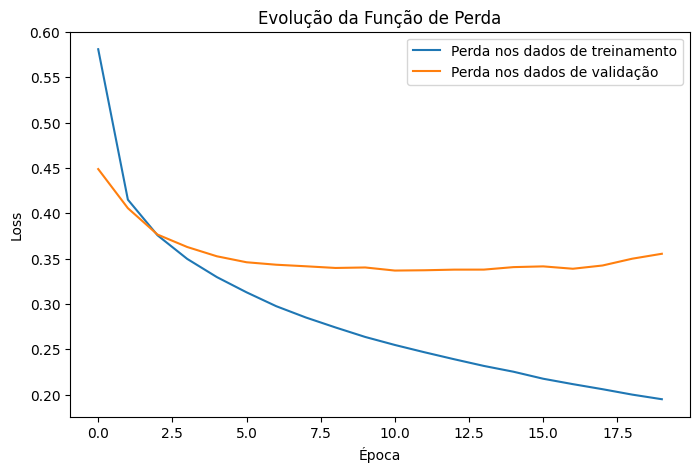

In [10]:
# Visualizar evolução da função de perda durante o treinamento

plt.figure(figsize=(8, 5))

plt.plot(historico.history["loss"], label="Perda nos dados de treinamento")
plt.plot(historico.history["val_loss"], label="Perda nos dados de validação")

# Configurar o gráfico

plt.xlabel("Época")
plt.ylabel("Loss")
plt.title("Evolução da Função de Perda")
plt.legend()

plt.show()

16. O que representam as curvas de perda nos dados de treinamento e de validação?

    R: As curvas representam a evolução do erro ao logo de cada treino.

17. Por que a perda nos dados de treinamento continua diminuindo ao longo das épocas?

    R: Os parametros são ajustados para corrigir os dados de treinamento.

18. A partir de aproximadamente qual época a perda de validação deixa de apresentar melhora significativa?

    R: A partir do 6 treinamento o desenvolvimento do modelo já não mais apresenta melhora significativa do modelo.


In [11]:
# Identificar a época com menor perda de validação

melhor_epoca = np.argmin(historico.history["val_loss"]) + 1
melhor_val_loss = np.min(historico.history["val_loss"])

print(f"Melhor época: {melhor_epoca}")
print(f"Menor val_loss: {melhor_val_loss:.4f}")

Melhor época: 11
Menor val_loss: 0.3367


# Uso do Modelo
Pegue imagens da internet e teste o modelo.

In [13]:
# Carregar e preparar uma nova imagem para classificação

imagem = keras.utils.load_img(
    "bota.png",
    color_mode="grayscale",
    target_size=(28, 28)
)

imagem = keras.utils.img_to_array(imagem)
imagem = imagem / 255.0
imagem = imagem.reshape(1, 784)

# Realizar classificação utilizando o modelo treinado

probabilidades = model.predict(imagem, verbose=0)
classe_prevista = np.argmax(probabilidades)

print(f"Classe prevista: {nomes_classes[classe_prevista]}")
print(f"Probabilidade: {probabilidades[0][classe_prevista] * 100:.2f}%")

Classe prevista: Bag
Probabilidade: 100.00%


## Pergunta
19. Por que o modelo classificou incorretamente a imagem da bota como Bag?

    R: Por que a imagem foi drasticamente reduzida e possui diferença do fundo que ficaria claro.

20. Como o modelo pode apresentar probabilidade de 100% e ainda assim estar errado?

    R: Porque a função Softmax força a soma das saídas a 100% distribuindo a confiança apenas entre as 10 classes conhecidas, o que gera probabilidades superestimadas mesmo diante de entradas fora da distribuição esperada.


# Taxa de Aprendizado e Função de Perda

In [14]:
# Construir modelo com nova arquitetura e taxa de aprendizado maior

model_lr = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: 128 neurônios com ReLU
    layers.Dense(64, activation="tanh"),         # 2ª camada oculta: 64 neurônios com Tanh
    layers.Dense(10, activation="softmax")       # Saída: Softmax
])

# Configurar processo de treinamento

model_lr.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.01),   # Taxa de aprendizado maior
    loss="sparse_categorical_crossentropy",                 # Função de perda
    metrics=["accuracy"]                                    # Métrica de avaliação
)

# Treinar modelo

historico_lr = model_lr.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.8067 - loss: 0.5274 - val_accuracy: 0.8493 - val_loss: 0.4209
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8503 - loss: 0.4136 - val_accuracy: 0.8600 - val_loss: 0.3868
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8598 - loss: 0.3851 - val_accuracy: 0.8643 - val_loss: 0.3905
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8672 - loss: 0.3635 - val_accuracy: 0.8602 - val_loss: 0.3793
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8693 - loss: 0.3599 - val_accuracy: 0.8613 - val_loss: 0.3868
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 10ms/step - accuracy: 0.8718 - loss: 0.3491 - val_accuracy: 0.8611 - val_loss: 0.3960
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8776 - loss: 0.3385 - val_accuracy: 0.8676 - val_loss: 0.3718
Epoch 8/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step - accuracy: 0.8757 - loss: 0.3411 - val_accuracy: 

## Perguntas
21. Qual hiperparâmetro de treinamento foi alterado em relação ao modelo de referência e qual foi a alteração realizada?

    R: Aumentou a taxa de aprendizado para 0.01

22. Comparando os dois treinamentos, que efeito o aumento da taxa de aprendizado produziu sobre o comportamento da loss e da accuracy?

    R: Ligeiramente piorou o desempenho do modelo

23. Quais hiperparâmetros de arquitetura também foram alterados em relação ao modelo de referência? Identifique as mudanças realizadas na quantidade de camadas ocultas, no número de neurônios e na função de ativação.

    R: Foi adicionado mais uma camada intermediária com 68 neuronios com função de ativação TanH

# Otimizador

In [ ]:
# Construir modelo com a mesma arquitetura e outro otimizador

model_sgd = keras.Sequential([
    layers.Input(shape=(784,)),                 # Dimensionalidade dos dados de entrada
    layers.Dense(128, activation="relu"),       # 1ª camada oculta: 128 neurônios com ReLU
    layers.Dense(64, activation="tanh"),        # 2ª camada oculta: 64 neurônios com Tanh
    layers.Dense(10, activation="softmax")      # Saída: Softmax
])

# Configurar processo de treinamento

model_sgd.compile(
    optimizer=keras.optimizers.SGD(learning_rate=0.01),    # Alterar apenas o otimizador
    loss="sparse_categorical_crossentropy",                # Manter função de perda
    metrics=["accuracy"]                                   # Métrica de avaliação
)

# Treinar modelo

historico_sgd = model_sgd.fit(
    X_train,
    y_train,
    epochs=20,
    batch_size=128,
    validation_split=0.20,
    verbose=1
)

Epoch 1/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.6588 - loss: 1.1264 - val_accuracy: 0.7479 - val_loss: 0.7799
Epoch 2/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.7749 - loss: 0.6991 - val_accuracy: 0.7903 - val_loss: 0.6324
Epoch 3/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8041 - loss: 0.5972 - val_accuracy: 0.8069 - val_loss: 0.5670
Epoch 4/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8168 - loss: 0.5450 - val_accuracy: 0.8158 - val_loss: 0.5298
Epoch 5/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8246 - loss: 0.5128 - val_accuracy: 0.8227 - val_loss: 0.5052
Epoch 6/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8299 - loss: 0.4903 - val_accuracy: 0.8273 - val_loss: 0.4872
Epoch 7/20
375/375 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - accuracy: 0.8350 - loss: 0.4731 - val_accuracy: 0.8320 - val_loss: 0.4732
Epoch 8/20


## Perguntas
24. Qual hiperparâmetro foi alterado em relação ao modelo anterior e qual foi a alteração realizada?

    R: o Otimizador foi alterado do Adam para o SGD

25. Mantendo a mesma arquitetura, a mesma taxa de aprendizado, a mesma função de perda, o mesmo número de épocas e o mesmo tamanho de lote, que diferenças podem ser observadas no treinamento com Adam e SGD?

    R: o SGD foi consideravelmente pior no desempenho do modelo

26. Considerando todo o laboratório, explique a diferença entre hiperparâmetros de arquitetura e hiperparâmetros de treinamento, citando exemplos utilizados nos modelos construídos.

    R: Hiperparametros de arquitetura definem a construção das camadas, como quantidade de camadas ocultas e neuronios e hiperparametros de treinamento definem quantidade de treinamentos/épocas, otimizadores, taxas de aprendizados, tamanhos de lotes de treinamento